In [ ]:
!pip install roboflow ultralytics

from roboflow import Roboflow
rf = Roboflow(api_key="CFPqVUZkUzpq8L3aQPhe")
project = rf.workspace("noora-alkhalaqi").project("bahraini-currency-2-hnw2l")
version = project.version(2)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...


In [ ]:
from ultralytics import YOLO
model = YOLO("yolo26s.pt")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

model.train(data = "/content/bahraini-currency-2-2/data.yaml", epochs = 10)

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bahraini-currency-2-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=F

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 5, 7, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x783929731390>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
     

In [ ]:
fintuned_model = YOLO("/content/runs/detect/train-3/weights/best.pt")


image 1/1 /content/bahraini-currency-2-2/test/images/0_5_0007_jpg.rf.25c613d0d87bb9eec199f65c67527e23.jpg: 640x640 1 0.5 BD, 23.6ms
Speed: 3.3ms preprocess, 23.6ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


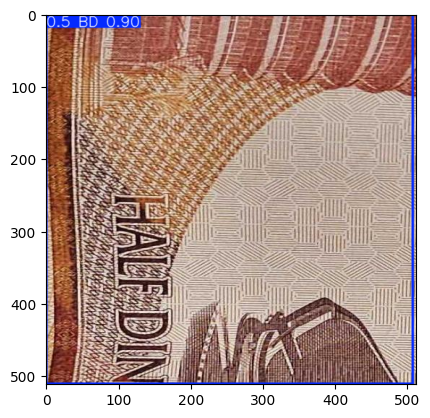

In [ ]:
results = fintuned_model("/content/bahraini-currency-2-2/test/images/0_5_0007_jpg.rf.25c613d0d87bb9eec199f65c67527e23.jpg")
plt.imshow(results[0].plot()[...,::-1])

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1869.6±737.7 MB/s, size: 52.9 KB)
val: Scanning /content/bahraini-currency-2-2/test/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 12.0Mit/s 0.0s
val: /content/bahraini-currency-2-2/test/images/10_0006_png.rf.641e459d31b5a578c01489a54d56c54b.jpg: 1 duplicate labels removed
val: /content/bahraini-currency-2-2/test/images/10_0006_png.rf.e8b53198a2e2ac1bad39ccf9a6d048b2.jpg: 1 duplicate labels removed
val: /content/bahraini-currency-2-2/test/images/10_0006_png.rf.e9ec58116fc6049742e6fdec8a63d897.jpg: 1 duplicate labels removed
val: /content/bahraini-currency-2-2/test/images/10_0006_png.rf.f1a2389a2624241257005dd95d854e1c.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%

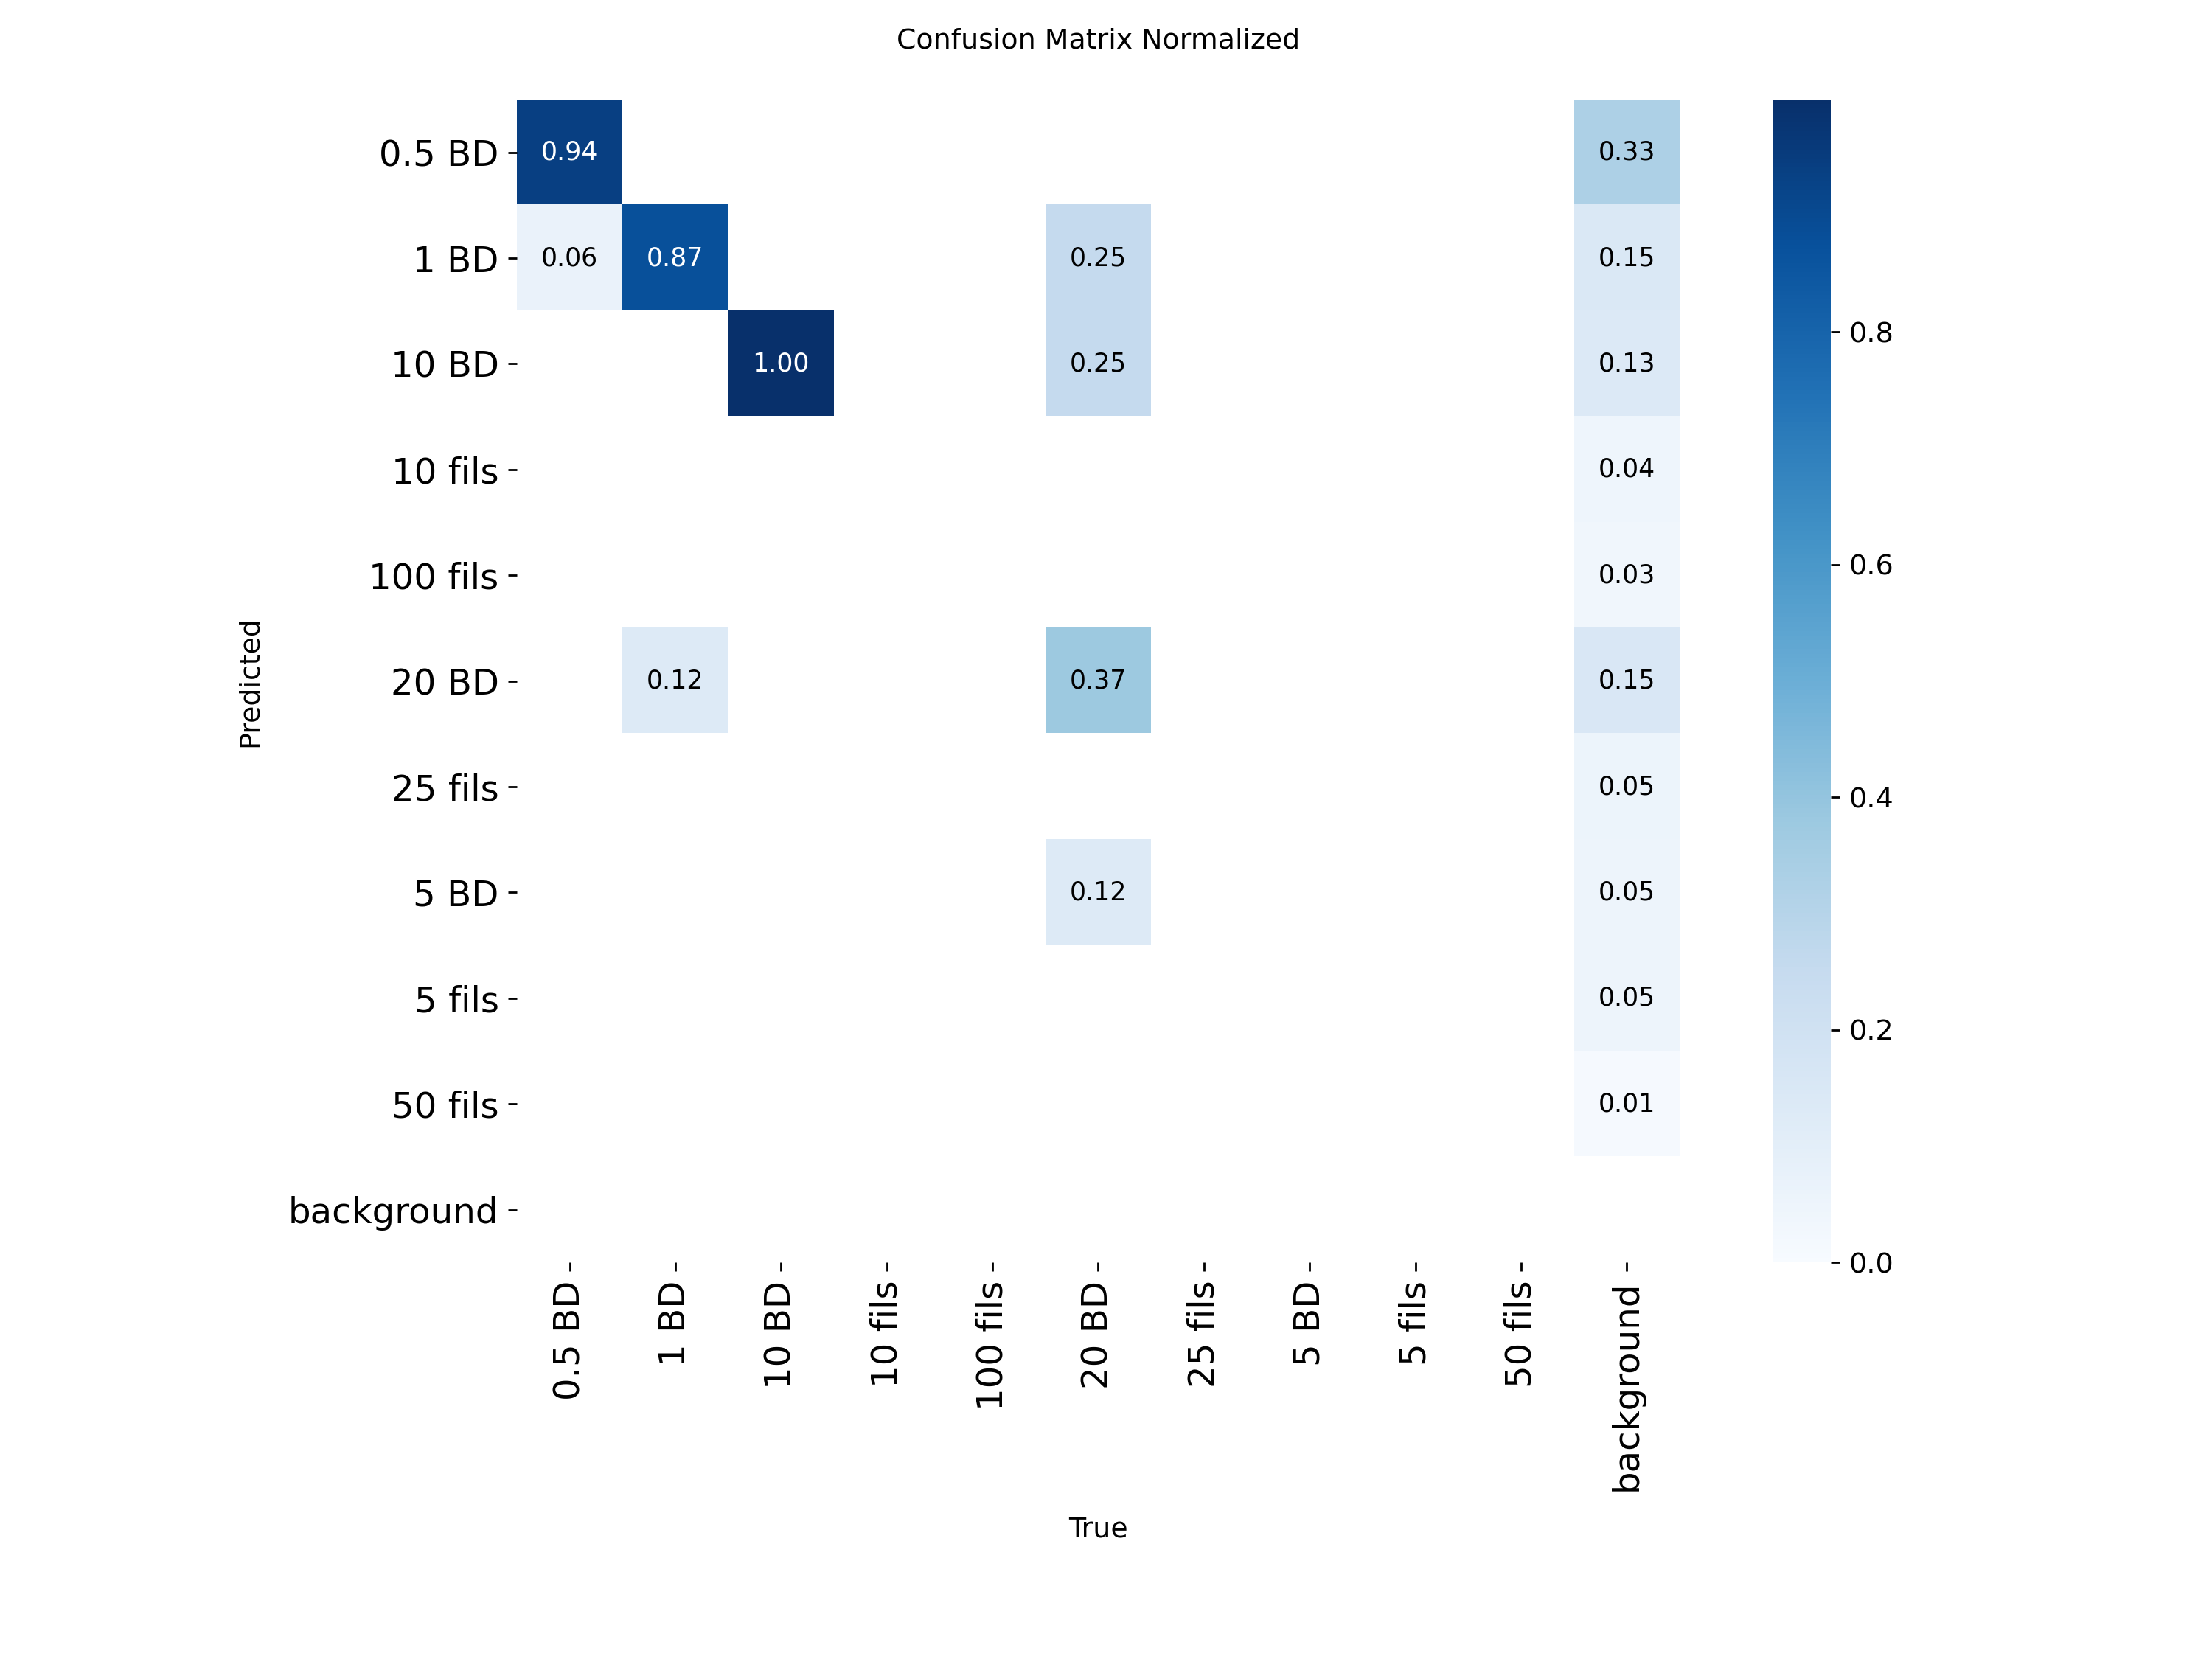

In [ ]:
## Evaluation
from IPython.display import Image, display
# per class performance
metrics = fintuned_model.val(data="/content/bahraini-currency-2-2/data.yaml", split="test")
# precision
print("Precision:", metrics.box.mp)
# recall
print("Recall:", metrics.box.mr)
# confision matrix
display(Image(f"{metrics.save_dir}/confusion_matrix_normalized.png"))